# Level 1 · Task 1 — Data Preprocessing for Machine Learning
**Codveda Technology — Machine Learning Internship**

**Goal:** take a raw dataset and make it ready for machine learning.

**Dataset:** `stock_prices.csv` — daily OHLCV prices for the 505 S&P 500 companies (2014–2017, ~497k rows).
It is the only provided dataset with real missing values, so it is a good fit for this task.

**Objectives covered**
1. Handle missing data (dropping vs. filling with median / domain values)
2. Encode categorical variables (one-hot encoding and label encoding)
3. Normalize / standardize numerical features
4. Split the dataset into training and testing sets

**ML target we prepare for:** will a stock close *higher tomorrow* than today? (binary: `1` = up, `0` = down/flat)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from pathlib import Path

sns.set_theme(style="whitegrid")
IMG = Path("images"); IMG.mkdir(exist_ok=True)
DATA = Path("../../data")

## 1. Load and inspect the raw data

In [2]:
df = pd.read_csv(DATA / "stock_prices.csv", parse_dates=["date"])
print("Shape:", df.shape)
print("Companies:", df["symbol"].nunique(), "| Date range:", df["date"].min().date(), "→", df["date"].max().date())
df.head()

Shape: (497472, 7)
Companies: 505 | Date range: 2014-01-02 → 2017-12-29


,symbol,date,open,high,low,close,volume
0,AAL,2014-01-02,25.0700,25.8200,25.0600,25.3600,8998943
1,AAPL,2014-01-02,79.3828,79.5756,78.8601,79.0185,58791957
2,AAP,2014-01-02,110.3600,111.8800,109.2900,109.7400,542711
3,ABBV,2014-01-02,52.1200,52.3300,51.5200,51.9800,4569061
4,ABC,2014-01-02,70.1100,70.2300,69.4800,69.8900,1148391


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 497472 entries, 0 to 497471
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   symbol  497472 non-null  str           
 1   date    497472 non-null  datetime64[us]
 2   open    497461 non-null  float64       
 3   high    497464 non-null  float64       
 4   low     497464 non-null  float64       
 5   close   497472 non-null  float64       
 6   volume  497472 non-null  int64         
dtypes: datetime64[us](1), float64(4), int64(1), str(1)
memory usage: 26.6 MB


In [4]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,497472,2016-01-06 17:16:00.439984,2014-01-02 00:00:00,2015-01-08 00:00:00,2016-01-11 00:00:00,2017-01-06 00:00:00,2017-12-29 00:00:00,NaN
open,497461.0,86.352275,1.62,41.69,64.97,98.41,2044.0,101.471228
high,497464.0,87.132562,1.69,42.09,65.56,99.23,2067.99,102.312062
low,497464.0,85.552467,1.5,41.28,64.3537,97.58,2035.11,100.570957
close,497472.0,86.369082,1.59,41.70375,64.98,98.42,2049.0,101.472407
volume,497472.0,4253610.897777,0.0,1080166.5,2084896.5,4271928.0,618237630.0,8232139.235883


## 2. Handle missing data

In [5]:
missing = df.isna().sum()
print(missing[missing > 0])
print(f"\nRows with at least one missing value: {df.isna().any(axis=1).sum()} "
      f"({df.isna().any(axis=1).mean():.4%} of the data)")
df[df.isna().any(axis=1)]

open    11
high     8
low      8
dtype: int64



Rows with at least one missing value: 11 (0.0022% of the data)


,symbol,date,open,high,low,close,volume
166348,VRTX,2015-05-12,NaN,NaN,NaN,124.0800,569747
175557,REGN,2015-06-09,NaN,NaN,NaN,526.0900,12135
182011,WRK,2015-06-26,NaN,NaN,NaN,61.9000,100
188547,DHR,2015-07-17,NaN,88.76,88.24,88.7200,2056819
188578,ES,2015-07-17,NaN,48.49,47.85,47.9200,1246786
188760,O,2015-07-17,NaN,47.31,46.83,46.9900,1229513
249223,DHR,2016-01-12,NaN,NaN,NaN,88.5500,0
249438,O,2016-01-12,NaN,NaN,NaN,52.4300,0
278801,UA,2016-04-07,NaN,NaN,NaN,41.5600,0
308365,FTV,2016-07-01,NaN,NaN,NaN,49.5400,0


Observations:
* Only `open`, `high` and `low` have gaps (27 cells in 11 rows) — `close` and `volume` are complete.
* Several of these rows have `volume == 0` (or a tiny volume such as 3 shares) → the stock did not really trade that day.
  These are data artefacts, not real trading days.

We compare the three standard strategies:

In [6]:
# Strategy A — drop every row that contains a missing value
dropped = df.dropna()
print("A) dropna        →", dropped.shape, f"(removed {len(df) - len(dropped)} rows)")

# Strategy B — fill with the column median (global statistic)
median_filled = df.copy()
num_cols = ["open", "high", "low"]
median_filled[num_cols] = SimpleImputer(strategy="median").fit_transform(median_filled[num_cols])
print("B) median fill   → remaining NaNs:", median_filled.isna().sum().sum())

# Strategy C — domain-aware fill: per-company median would still be far from that day's price,
# so we use the same day's close (open/high/low are always close to it on a single day)
domain_filled = df.copy()
for c in num_cols:
    domain_filled[c] = domain_filled[c].fillna(domain_filled["close"])
print("C) fill w/ close → remaining NaNs:", domain_filled.isna().sum().sum())

A) dropna        → (497461, 7) (removed 11 rows)


B) median fill   → remaining NaNs: 0


C) fill w/ close → remaining NaNs: 0


In [7]:
# Why the global median is a bad idea for prices: compare the filled value with the real close of that day
idx = df[df["open"].isna()].index
cmp = pd.DataFrame({
    "symbol": df.loc[idx, "symbol"],
    "close (true level)": df.loc[idx, "close"],
    "open — median fill": median_filled.loc[idx, "open"],
    "open — close fill": domain_filled.loc[idx, "open"],
})
cmp

,symbol,close (true level),open — median fill,open — close fill
166348,VRTX,124.0800,64.97,124.0800
175557,REGN,526.0900,64.97,526.0900
182011,WRK,61.9000,64.97,61.9000
188547,DHR,88.7200,64.97,88.7200
188578,ES,47.9200,64.97,47.9200
188760,O,46.9900,64.97,46.9900
249223,DHR,88.5500,64.97,88.5500
249438,O,52.4300,64.97,52.4300
278801,UA,41.5600,64.97,41.5600
308365,FTV,49.5400,64.97,49.5400


**Decision**
* Rows with `volume == 0` are non-trading days → **drop** them (they would also create fake 0 % returns).
* Remaining gaps → **fill with that day's close** (strategy C). The global median puts e.g. a $526 stock at ~$60,
  which would create huge fake price moves.

In [8]:
clean = df[df["volume"] > 0].copy()
for c in num_cols:
    clean[c] = clean[c].fillna(clean["close"])
# keep high/low consistent after filling
clean["high"] = clean[["high", "open", "close"]].max(axis=1)
clean["low"] = clean[["low", "open", "close"]].min(axis=1)

print("Rows removed (volume == 0):", len(df) - len(clean))
print("Missing values left:", clean.isna().sum().sum())
print("Duplicate (symbol, date) rows:", clean.duplicated(["symbol", "date"]).sum())

Rows removed (volume == 0): 4


Missing values left: 0


Duplicate (symbol, date) rows: 0


## 3. Feature engineering + target
Raw prices are not comparable between companies ($5 vs $1,000 stocks), so we build scale-free features.

In [9]:
clean = clean.sort_values(["symbol", "date"]).reset_index(drop=True)
g = clean.groupby("symbol")

clean["return_1d"] = g["close"].pct_change()                       # today's return
clean["return_5d"] = g["close"].pct_change(5)                      # weekly momentum
clean["intraday_range"] = (clean["high"] - clean["low"]) / clean["close"]
clean["open_close_gap"] = (clean["close"] - clean["open"]) / clean["open"]
clean["log_volume"] = np.log1p(clean["volume"])
clean["volume_ratio"] = clean["volume"] / g["volume"].transform(lambda v: v.rolling(20, min_periods=5).mean())
clean["volatility_10d"] = g["return_1d"].transform(lambda r: r.rolling(10, min_periods=5).std())
clean["weekday"] = clean["date"].dt.day_name()
clean["month"] = clean["date"].dt.month

# Target: does tomorrow's close beat today's close?
clean["next_close"] = g["close"].shift(-1)
clean["target_up"] = (clean["next_close"] > clean["close"]).astype(int)

# Rolling features / the target are undefined for the first & last days of each company → drop those rows
model_df = clean.dropna(subset=["return_5d", "volume_ratio", "volatility_10d", "next_close"]).copy()
print(model_df.shape)
print("Target balance:\n", model_df["target_up"].value_counts(normalize=True).round(3))
model_df.head()

(494438, 18)
Target balance:
 target_up
1    0.519
0    0.481
Name: proportion, dtype: float64


,symbol,date,open,high,low,close,volume,return_1d,return_5d,intraday_range,open_close_gap,log_volume,volume_ratio,volatility_10d,weekday,month,next_close,target_up
5,A,2014-01-09,58.40,58.680,57.870,58.41,1757647,0.000343,0.039139,0.013867,0.000171,14.379487,0.921794,0.009438,Thursday,1,58.93,1
6,A,2014-01-10,58.51,59.010,58.140,58.93,1623330,0.008903,0.035313,0.014763,0.007178,14.299991,0.869823,0.008455,Friday,1,58.93,0
7,A,2014-01-13,58.77,59.100,58.600,58.93,2946738,0.000000,0.040431,0.008485,0.002722,14.896210,1.472387,0.008280,Monday,1,59.88,1
8,A,2014-01-14,59.16,59.950,59.020,59.88,2562236,0.016121,0.042298,0.015531,0.012170,14.756391,1.241600,0.008344,Tuesday,1,60.34,1
9,A,2014-01-15,59.82,60.365,59.585,60.34,2335194,0.007682,0.033396,0.012927,0.008693,14.663606,1.116885,0.007806,Wednesday,1,60.50,1


## 4. Encode categorical variables
We have two categorical columns:
* `weekday` — 5 categories, no natural order → **one-hot encoding**
* `symbol` — 505 categories → one-hot would add 505 sparse columns, so we show **label encoding** (an integer id per company),
  which tree-based models handle well.

In [10]:
# One-hot encoding (weekday)
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
weekday_ohe = ohe.fit_transform(model_df[["weekday"]])
pd.DataFrame(weekday_ohe, columns=ohe.get_feature_names_out()).head()

,weekday_Friday,weekday_Monday,weekday_Thursday,weekday_Tuesday,weekday_Wednesday
0,0.0,0.0,1.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0
2,0.0,1.0,0.0,0.0,0.0
3,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,0.0,1.0


In [11]:
# Label encoding (symbol)
le = LabelEncoder()
model_df["symbol_id"] = le.fit_transform(model_df["symbol"])
print("Number of classes:", len(le.classes_))
model_df[["symbol", "symbol_id"]].drop_duplicates().head(8)

Number of classes: 505


,symbol,symbol_id
5,A,0
1012,AAL,1
2019,AAP,2
3026,AAPL,3
4033,ABBV,4
5040,ABC,5
6047,ABT,6
7054,ACN,7


## 5. Normalize / standardize numerical features

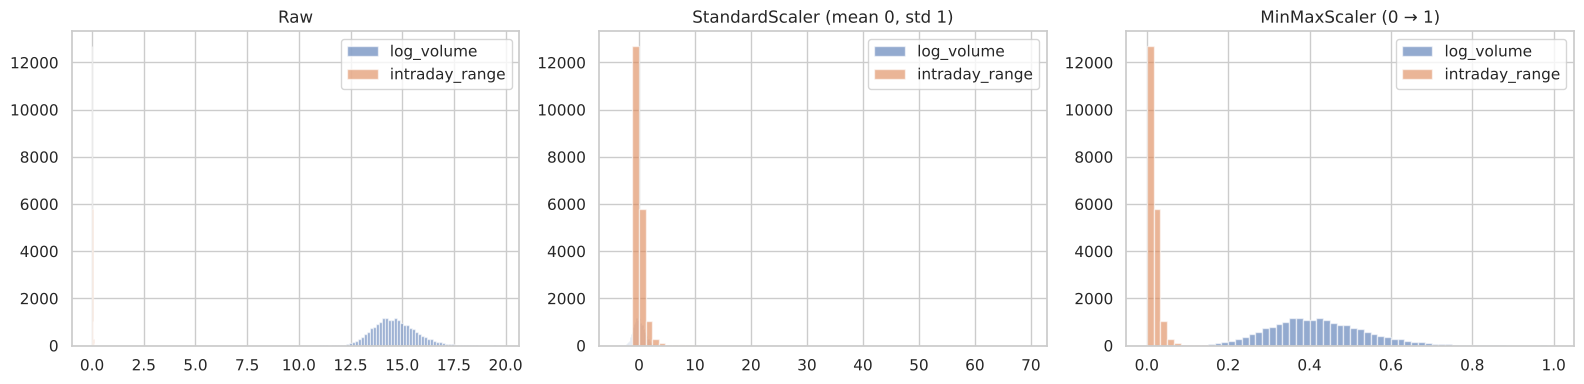

In [12]:
numeric_features = ["return_1d", "return_5d", "intraday_range", "open_close_gap",
                    "log_volume", "volume_ratio", "volatility_10d"]

# Compare the two scalers on two features
demo = model_df[["log_volume", "intraday_range"]].sample(20000, random_state=42)
std_demo = StandardScaler().fit_transform(demo)
mm_demo = MinMaxScaler().fit_transform(demo)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, data, title in zip(axes, [demo.values, std_demo, mm_demo],
                           ["Raw", "StandardScaler (mean 0, std 1)", "MinMaxScaler (0 → 1)"]):
    ax.hist(data[:, 0], bins=60, alpha=.6, label="log_volume")
    ax.hist(data[:, 1], bins=60, alpha=.6, label="intraday_range")
    ax.set_title(title); ax.legend()
plt.tight_layout(); plt.savefig(IMG / "scaling_comparison.png", dpi=120); plt.show()

`StandardScaler` is our choice: features like returns are centred around 0 and have outliers, and MinMax scaling would squash
most values into a tiny range because of those outliers.

## 6. Train / test split
Two options are shown:
* **Random stratified split** (`train_test_split`) — the standard approach for independent rows.
* **Chronological split** — the correct choice for time series: train on the past (2014–2016), test on the future (2017).
  A random split would leak future information into training.

In [13]:
feature_cols = numeric_features + ["weekday", "symbol_id", "month"]
X = model_df[feature_cols]
y = model_df["target_up"]

# Option 1 — random stratified split
X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Random split     → train", X_tr_r.shape, "| test", X_te_r.shape)

# Option 2 — chronological split (used from here on)
train_mask = model_df["date"] < "2017-01-01"
X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]
print("Time-based split → train", X_train.shape, "| test", X_test.shape)

Random split     → train (395550, 10) | test (98888, 10)
Time-based split → train (368941, 10) | test (125497, 10)


## 7. Full reusable preprocessing pipeline
Everything above in one `ColumnTransformer`. It is **fit on the training set only** and then applied to the test set,
so no information from the test data leaks into the scaler/imputer.

In [14]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), numeric_features),
    ("weekday", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["weekday"]),
    ("pass", "passthrough", ["symbol_id", "month"]),
])

X_train_ready = preprocessor.fit_transform(X_train)
X_test_ready = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
X_train_ready_df = pd.DataFrame(X_train_ready, columns=feature_names)
print("Train matrix:", X_train_ready.shape, "| Test matrix:", X_test_ready.shape)
print("Any NaN left:", np.isnan(X_train_ready).any() or np.isnan(X_test_ready).any())
X_train_ready_df.describe().T.round(3)

Train matrix: (368941, 14) | Test matrix: (125497, 14)
Any NaN left: False


,count,mean,std,min,25%,50%,75%,max
num__return_1d,368941.0,-0.000,1.000,-37.043,-0.459,0.008,0.473,59.660
num__return_5d,368941.0,0.000,1.000,-17.104,-0.488,0.010,0.498,28.244
num__intraday_range,368941.0,-0.000,1.000,-1.539,-0.606,-0.252,0.297,75.669
num__open_close_gap,368941.0,-0.000,1.000,-35.327,-0.495,0.007,0.508,57.773
num__log_volume,368941.0,0.000,1.000,-4.936,-0.693,-0.063,0.618,5.289
num__volume_ratio,368941.0,0.000,1.000,-2.023,-0.581,-0.200,0.323,26.372
num__volatility_10d,368941.0,-0.000,1.000,-1.528,-0.613,-0.231,0.324,40.239
weekday__weekday_Friday,368941.0,0.198,0.399,0.000,0.000,0.000,0.000,1.000
weekday__weekday_Monday,368941.0,0.188,0.391,0.000,0.000,0.000,0.000,1.000
weekday__weekday_Thursday,368941.0,0.201,0.401,0.000,0.000,0.000,0.000,1.000


In [15]:
# Save a sample of the processed data + the fitted preprocessor for later use
import joblib
Path("output").mkdir(exist_ok=True)
X_train_ready_df.assign(target_up=y_train.values).sample(5000, random_state=42).to_csv(
    "output/processed_train_sample.csv", index=False)
joblib.dump(preprocessor, "output/preprocessor.joblib")
print("Saved output/processed_train_sample.csv and output/preprocessor.joblib")

Saved output/processed_train_sample.csv and output/preprocessor.joblib


## Summary
| Step | What was done |
|---|---|
| Missing data | 27 missing cells in 11 rows. Non-trading rows (`volume = 0`) dropped; remaining gaps filled with the same-day close (shown to be far better than a global median fill). |
| Feature engineering | 7 scale-free numeric features (returns, range, volume ratio, volatility) + target `target_up`. |
| Categorical encoding | `weekday` → one-hot (5 columns); `symbol` → label encoding (505 ids). |
| Scaling | `StandardScaler` on numeric features, fit on train only. |
| Split | Chronological split: 2014–2016 train, 2017 test (random stratified split also shown). |

The output matrices `X_train_ready` / `X_test_ready` contain no missing values and are ready for any scikit-learn model.